# 2. Entrenamiento de los modelos de referencia

En esta notebook se entrenan y comparan los modelos de referencia, EfficientNet-B0, ConvNeXt-Tiny y Swin-Tiny, en las mismas condiciones.

## Condiciones comunes

Se usa BCE sin ponderar y AdamW con tasas distintas para el extractor y la cabeza. El lote es de 8 imágenes y se acumulan gradientes hasta un lote efectivo de 32. 

La tasa se calienta durante dos épocas y luego baja por coseno. El máximo es de 30 épocas, con parada tras cinco sin mejora.

In [ ]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.nn import functional as F
from torch.optim import AdamW
from torch.utils.data import DataLoader
from torchinfo import summary
from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    EfficientNet_B0_Weights,
    Swin_T_Weights,
)

from photovoltaic_xai import CLASS_NAMES, MODEL_NAMES, PROTOCOL_ID
from photovoltaic_xai.balance import BalancedPatternSampler, BalancePlan
from photovoltaic_xai.dataset import PairedELTransform, PVELADDataset
from photovoltaic_xai.metrics import compute_metrics, optimize_thresholds
from photovoltaic_xai.models import (
    checkpoint_hash,
    create_model,
    load_run,
    parameter_groups,
    predict,
    recalibrate_batchnorm,
    save_run,
    seed_everything,
    warmup_cosine,
)
from photovoltaic_xai.notebook_support import figure_style, project_root, show_figure
from photovoltaic_xai.preparation import load_preparation

PROJECT_ROOT = project_root()
RUN_DIR = PROJECT_ROOT / "outputs/experiments"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG = {
    "seed": 42,
    "image_size": 512,
    "batch_size": 8,
    "effective_batch_size": 32,
    "lr_backbone": 1e-4,
    "lr_head": 5e-4,
    "weight_decay": 0.01,
    "amp": True,
    "max_epochs": 30,
    "patience": 5,
    "warmup_epochs": 2,
}
prepared = load_preparation(PROJECT_ROOT)
norm = prepared["normalization"]
train_records = [record for record in prepared["records"] if record["split"] == "train"]
val_records = [record for record in prepared["records"] if record["split"] == "val"]
assert CONFIG["image_size"] == norm["image_size"]
display(pd.Series(CONFIG, name="Configuración común"))
print("Dispositivo:", device)

seed                        42
image_size                 512
batch_size                   8
effective_batch_size        32
lr_backbone             0.0001
lr_head                 0.0005
weight_decay              0.01
amp                       True
max_epochs                  30
patience                     5
warmup_epochs                2
Name: Configuración común, dtype: object

Dispositivo: cuda


Se preparan tres cargadores de imágenes con la misma normalización. El de entrenamiento aplica aumentos y muestreo balanceado, y el de validación usa un preprocesado fijo. Al final de cada época, el cargador de calibración recorre las imágenes originales de entrenamiento con ese mismo preprocesado. Así, las medias y varianzas de BatchNorm que EfficientNet-B0 usa en validación reflejan la distribución original de los datos.

In [2]:
train_transform = PairedELTransform(
    CONFIG["image_size"], mean=norm["mean"], std=norm["std"], training=True
)
val_transform = PairedELTransform(CONFIG["image_size"], mean=norm["mean"], std=norm["std"])
train_set = PVELADDataset(train_records, PROJECT_ROOT, train_transform)
val_set = PVELADDataset(val_records, PROJECT_ROOT, val_transform)
sampler = BalancedPatternSampler(
    [record["labels"] for record in train_records],
    BalancePlan.from_dict(prepared["balance"]),
    ids=[record["id"] for record in train_records],
)
train_loader = DataLoader(train_set, batch_size=CONFIG["batch_size"], sampler=sampler)
val_loader = DataLoader(val_set, batch_size=CONFIG["batch_size"], shuffle=False)

# Clean training originals reestimate BatchNorm.
calibration_set = PVELADDataset(train_records, PROJECT_ROOT, val_transform)
calibration_order = np.random.default_rng(CONFIG["seed"]).permutation(len(calibration_set)).tolist()
calibration_loader = DataLoader(
    calibration_set,
    batch_size=CONFIG["batch_size"],
    sampler=calibration_order,
    generator=torch.Generator().manual_seed(CONFIG["seed"]),
)

runs, histories = {}, {}

## Función de entrenamiento y validación

Esta celda define `train_reference`, la función que se llama para entrenar cada modelo. En cada época, el modelo procesa las imágenes por lotes y compara sus predicciones con las etiquetas mediante la función de pérdida BCE. AdamW actualiza los pesos con los gradientes acumulados.

Al final de cada época, la función evalúa el modelo en validación y registra la pérdida y la mAP. Guarda los pesos de la época con mayor mAP y usa sus predicciones de validación para elegir el umbral de cada defecto. Si ya hay una ejecución compatible, recupera sus resultados y su historial. Esto último para poder hacer pruebas con los modelos sin tener que volver a entrenarlos desde cero.

In [3]:
def train_reference(model_name, weights):
    output = RUN_DIR / model_name
    config = CONFIG | {"model_name": model_name, "device": str(device)}

    if (output / "run.json").is_file():
        # Completed checkpoints and thresholds are reused automatically, without loading a GPU.
        run, _ = load_run(output, prepared)
        saved_config = {key: value for key, value in run["config"].items() if key != "device"}
        current_config = {key: value for key, value in config.items() if key != "device"}
        if saved_config != current_config:
            raise ValueError("Saved reference settings differ; existing results are preserved")
        if not (output / "best.pt").is_file() or not (output / "history.csv").is_file():
            raise FileNotFoundError("A completed reference is missing its checkpoint or history")
        print("Resultados de entrenamiento y validación recuperados.")
        return run, pd.read_csv(output / "history.csv")

    if output.exists() and any(output.iterdir()):
        raise ValueError("An incomplete reference directory will not be overwritten")
    output.mkdir(parents=True, exist_ok=True)
    seed_everything(config["seed"])
    model = create_model(model_name, weights=weights).to(device).eval()
    criterion = nn.BCEWithLogitsLoss()
    optimizer = AdamW(
        parameter_groups(model, config["lr_backbone"], config["lr_head"]),
        weight_decay=config["weight_decay"],
    )
    accumulation = config["effective_batch_size"] // config["batch_size"]
    assert accumulation >= 1 and config["effective_batch_size"] % config["batch_size"] == 0
    updates_per_epoch = math.ceil(len(train_loader) / accumulation)
    total_updates = config["max_epochs"] * updates_per_epoch
    warmup_updates = config["warmup_epochs"] * updates_per_epoch
    scheduler = warmup_cosine(optimizer, warmup_updates, total_updates)
    use_amp = config["amp"] and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    run = {
        "protocol_id": PROTOCOL_ID,
        "training_protocol": "epochs-bn-recalibration-v1",
        "evaluation_precision": "float32",
        "selection_ranking": "sigmoid-float32",
        "class_names": list(CLASS_NAMES),
        "config": config,
        "loss": "bce",
        "validation_loss": "bce",
        "balanced": True,
        "metadata": {"data_fingerprint": prepared["data_fingerprint"]},
        "status": "running",
        "completed_epochs": 0,
        "completed_updates": 0,
    }
    save_run(output, run)
    history, best_map, stale_epochs = [], -math.inf, 0
    if device.type == "cuda":
        torch.cuda.synchronize(device)
        torch.cuda.reset_peak_memory_stats(device)
    started = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        train_loader.sampler.set_epoch(epoch - 1)
        model.train()
        optimizer.zero_grad(set_to_none=True)
        epoch_updates = run["completed_updates"]
        loss_sum, image_count, accumulated = 0.0, 0, 0
        learning_rates = [group["lr"] for group in optimizer.param_groups]

        for batch_index, batch in enumerate(train_loader):
            images, labels = batch["image"].to(device), batch["labels"].to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; training remains incomplete")
            count = len(images)
            scaler.scale(loss * count).backward()
            loss_sum += float(loss.detach()) * count
            image_count += count
            accumulated += count
            if (batch_index + 1) % accumulation == 0 or batch_index + 1 == len(train_loader):
                scaler.unscale_(optimizer)
                for parameter in model.parameters():
                    if parameter.grad is not None:
                        parameter.grad.div_(accumulated)
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                if scaler.get_scale() >= previous_scale:
                    run["completed_updates"] += 1
                    scheduler.step()
                optimizer.zero_grad(set_to_none=True)
                accumulated = 0
        if run["completed_updates"] == epoch_updates:
            raise RuntimeError("No effective optimizer update; check AMP stability")

        # Only BatchNorm uses batch statistics during clean calibration.
        calibration_started = time.perf_counter()
        calibration_images = recalibrate_batchnorm(model, calibration_loader, device)
        if calibration_images:
            assert calibration_images == len(train_records)
        calibration_seconds = time.perf_counter() - calibration_started

        # Historical reference selection ranks sigmoid FP32; final reports use logits.
        validation = predict(model, val_loader, device=device)
        val_loss = F.binary_cross_entropy_with_logits(
            torch.from_numpy(validation["logits"]), torch.from_numpy(validation["labels"])
        ).item()
        val_map = compute_metrics(validation["labels"], validation["probabilities"])["overall"][
            "map"
        ]
        if val_map > best_map:
            best_map, stale_epochs = val_map, 0
            run.update(best_epoch=epoch, best_map=best_map)
            torch.save(model.state_dict(), output / "best.pt")
            np.savez_compressed(
                output / "validation.npz",
                ids=np.asarray(validation["ids"]),
                labels=validation["labels"],
                logits=validation["logits"],
                checkpoint_sha256=checkpoint_hash(output),
            )
        else:
            stale_epochs += 1
        history.append(
            {
                "epoch": epoch,
                "train_loss": loss_sum / image_count,
                "val_loss": val_loss,
                "val_map": val_map,
                "lr_backbone": learning_rates[0],
                "lr_head": learning_rates[-1],
                "optimizer_updates": run["completed_updates"],
                "bn_calibration_images": calibration_images,
                "bn_calibration_seconds": calibration_seconds,
            }
        )
        run["completed_epochs"] = epoch
        print(
            f"Epoch {epoch}: train_BCE={loss_sum / image_count:.4f}, val_BCE={val_loss:.4f}, mAP={val_map:.6f}"
        )
        if stale_epochs >= config["patience"]:
            break

    if device.type == "cuda":
        torch.cuda.synchronize(device)
    run["training_cost"] = {
        "training_seconds": time.perf_counter() - started,
        "bn_calibration_seconds": sum(row["bn_calibration_seconds"] for row in history),
        "training_peak_allocated_bytes": torch.cuda.max_memory_allocated(device)
        if device.type == "cuda"
        else None,
        "device": torch.cuda.get_device_name(device) if device.type == "cuda" else "cpu",
    }
    run["stop_reason"] = "early_stopping" if stale_epochs >= config["patience"] else "max_epochs"
    with np.load(output / "validation.npz", allow_pickle=False) as saved:
        validation = {key: saved[key] for key in ("ids", "labels", "logits")}
    validation["probabilities"] = torch.from_numpy(validation["logits"]).sigmoid().numpy()
    thresholds = optimize_thresholds(validation["labels"], validation["probabilities"], split="val")
    run.update(
        status="complete",
        metrics=compute_metrics(
            validation["labels"],
            validation["probabilities"],
            thresholds,
            logits=validation["logits"],
        ),
        metrics_ranking="logits",
    )
    pd.DataFrame(history).to_csv(output / "history.csv", index=False)
    save_run(output, run)
    del model, optimizer, scheduler, scaler
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return run, pd.DataFrame(history)

## Entrenamiento de los modelos de referencia

Con la función `train_reference`, procedemos a entrenar cada uno de los modelos de referencia.

### EfficientNet-B0

In [4]:
model_name = "efficientnet_b0"
model = create_model(model_name)
display(summary(model, depth=3, col_names=("num_params", "trainable"), verbose=0))
del model

runs[model_name], histories[model_name] = train_reference(
    model_name, EfficientNet_B0_Weights.IMAGENET1K_V1
)

Layer (type:depth-idx)                                  Param #                   Trainable
EfficientNet                                            --                        True
├─Sequential: 1-1                                       --                        True
│    └─Conv2dNormActivation: 2-1                        --                        True
│    │    └─Conv2d: 3-1                                 864                       True
│    │    └─BatchNorm2d: 3-2                            64                        True
│    │    └─SiLU: 3-3                                   --                        --
│    └─Sequential: 2-2                                  --                        True
│    │    └─MBConv: 3-4                                 1,448                     True
│    └─Sequential: 2-3                                  --                        True
│    │    └─MBConv: 3-5                                 6,004                     True
│    │    └─MBConv: 3-6                 

Epoch 1: train_BCE=0.3814, val_BCE=0.2214, mAP=0.671043
Epoch 2: train_BCE=0.1706, val_BCE=0.1483, mAP=0.730676
Epoch 3: train_BCE=0.1249, val_BCE=0.1129, mAP=0.872852
Epoch 4: train_BCE=0.0867, val_BCE=0.0929, mAP=0.931623
Epoch 5: train_BCE=0.0709, val_BCE=0.0881, mAP=0.937340
Epoch 6: train_BCE=0.0599, val_BCE=0.0769, mAP=0.944156
Epoch 7: train_BCE=0.0549, val_BCE=0.0766, mAP=0.941811
Epoch 8: train_BCE=0.0506, val_BCE=0.0885, mAP=0.952314
Epoch 9: train_BCE=0.0473, val_BCE=0.0655, mAP=0.952461
Epoch 10: train_BCE=0.0440, val_BCE=0.0865, mAP=0.948442
Epoch 11: train_BCE=0.0448, val_BCE=0.0597, mAP=0.958127
Epoch 12: train_BCE=0.0403, val_BCE=0.0770, mAP=0.957830
Epoch 13: train_BCE=0.0401, val_BCE=0.0672, mAP=0.960212
Epoch 14: train_BCE=0.0363, val_BCE=0.0709, mAP=0.963290
Epoch 15: train_BCE=0.0370, val_BCE=0.0702, mAP=0.962603
Epoch 16: train_BCE=0.0357, val_BCE=0.0614, mAP=0.961507
Epoch 17: train_BCE=0.0321, val_BCE=0.0687, mAP=0.963876
Epoch 18: train_BCE=0.0325, val_BCE=0.05

### ConvNeXt-Tiny

In [5]:
model_name = "convnext_tiny"
model = create_model(model_name)
display(summary(model, depth=3, col_names=("num_params", "trainable"), verbose=0))
del model

runs[model_name], histories[model_name] = train_reference(
    model_name, ConvNeXt_Tiny_Weights.IMAGENET1K_V1
)

Layer (type:depth-idx)                        Param #                   Trainable
ConvNeXt                                      --                        True
├─Sequential: 1-1                             --                        True
│    └─Conv2dNormActivation: 2-1              --                        True
│    │    └─Conv2d: 3-1                       4,704                     True
│    │    └─LayerNorm2d: 3-2                  192                       True
│    └─Sequential: 2-2                        --                        True
│    │    └─CNBlock: 3-3                      79,296                    True
│    │    └─CNBlock: 3-4                      79,296                    True
│    │    └─CNBlock: 3-5                      79,296                    True
│    └─Sequential: 2-3                        --                        True
│    │    └─LayerNorm2d: 3-6                  192                       True
│    │    └─Conv2d: 3-7                       73,920                   

Epoch 1: train_BCE=0.2686, val_BCE=0.1935, mAP=0.720796
Epoch 2: train_BCE=0.1068, val_BCE=0.0686, mAP=0.944868
Epoch 3: train_BCE=0.0622, val_BCE=0.0910, mAP=0.953083
Epoch 4: train_BCE=0.0545, val_BCE=0.0609, mAP=0.956585
Epoch 5: train_BCE=0.0485, val_BCE=0.0913, mAP=0.953591
Epoch 6: train_BCE=0.0451, val_BCE=0.0788, mAP=0.958631
Epoch 7: train_BCE=0.0413, val_BCE=0.0683, mAP=0.960824
Epoch 8: train_BCE=0.0381, val_BCE=0.0747, mAP=0.962790
Epoch 9: train_BCE=0.0371, val_BCE=0.0682, mAP=0.955181
Epoch 10: train_BCE=0.0319, val_BCE=0.0583, mAP=0.963004
Epoch 11: train_BCE=0.0327, val_BCE=0.0624, mAP=0.965753
Epoch 12: train_BCE=0.0289, val_BCE=0.0749, mAP=0.961289
Epoch 13: train_BCE=0.0307, val_BCE=0.0501, mAP=0.963824
Epoch 14: train_BCE=0.0253, val_BCE=0.0710, mAP=0.961929
Epoch 15: train_BCE=0.0251, val_BCE=0.0728, mAP=0.960319
Epoch 16: train_BCE=0.0223, val_BCE=0.0574, mAP=0.964859


### Swin-Tiny

In [6]:
model_name = "swin_t"
model = create_model(model_name)
display(summary(model, depth=3, col_names=("num_params", "trainable"), verbose=0))
del model

runs[model_name], histories[model_name] = train_reference(model_name, Swin_T_Weights.IMAGENET1K_V1)

Layer (type:depth-idx)                             Param #                   Trainable
SwinTransformer                                    --                        True
├─Sequential: 1-1                                  --                        True
│    └─Sequential: 2-1                             --                        True
│    │    └─Conv2d: 3-1                            4,704                     True
│    │    └─Permute: 3-2                           --                        --
│    │    └─LayerNorm: 3-3                         192                       True
│    └─Sequential: 2-2                             --                        True
│    │    └─SwinTransformerBlock: 3-4              112,347                   True
│    │    └─SwinTransformerBlock: 3-5              112,347                   True
│    └─PatchMerging: 2-3                           --                        True
│    │    └─Linear: 3-6                            73,728                    True
│    │    └─L

Epoch 1: train_BCE=0.2640, val_BCE=0.2209, mAP=0.716202
Epoch 2: train_BCE=0.1325, val_BCE=0.1426, mAP=0.802257
Epoch 3: train_BCE=0.0995, val_BCE=0.1958, mAP=0.915681
Epoch 4: train_BCE=0.0786, val_BCE=0.0963, mAP=0.940805
Epoch 5: train_BCE=0.0643, val_BCE=0.0977, mAP=0.934575
Epoch 6: train_BCE=0.0619, val_BCE=0.0809, mAP=0.947326
Epoch 7: train_BCE=0.0573, val_BCE=0.0890, mAP=0.943402
Epoch 8: train_BCE=0.0540, val_BCE=0.1173, mAP=0.945929
Epoch 9: train_BCE=0.0519, val_BCE=0.0908, mAP=0.946800
Epoch 10: train_BCE=0.0488, val_BCE=0.0881, mAP=0.947657
Epoch 11: train_BCE=0.0476, val_BCE=0.1038, mAP=0.954390
Epoch 12: train_BCE=0.0420, val_BCE=0.0864, mAP=0.955869
Epoch 13: train_BCE=0.0426, val_BCE=0.0642, mAP=0.956095
Epoch 14: train_BCE=0.0405, val_BCE=0.0818, mAP=0.954369
Epoch 15: train_BCE=0.0385, val_BCE=0.1111, mAP=0.952732
Epoch 16: train_BCE=0.0396, val_BCE=0.0998, mAP=0.951405
Epoch 17: train_BCE=0.0351, val_BCE=0.0673, mAP=0.960694
Epoch 18: train_BCE=0.0342, val_BCE=0.05

## Rendimiento global en validación

Tras entrenar cada modelo, se muestra una tabla comparativa con sus métricas de validación. La mAP resume cómo se ordenan los positivos de los seis defectos. La última columna indica la proporción de imágenes sanas en las que se predijo algún defecto.

In [7]:
reports = {name: runs[name]["metrics"] for name in MODEL_NAMES}
comparison = {
    name: report["overall"]
    | {
        "healthy_false_positive_rate": report["healthy"]["false_positive_rate_any_label"],
    }
    for name, report in reports.items()
}
display(pd.DataFrame.from_dict(comparison, orient="index").rename_axis("model"))

,num_classes,map,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,hamming_loss,subset_accuracy,healthy_false_positive_rate
model,,,,,,,,,,,
efficientnet_b0,6,0.964571,0.957119,0.919726,0.936848,0.966544,0.930150,0.947998,0.012467,0.9300,0.014076
convnext_tiny,6,0.965752,0.940092,0.937521,0.938727,0.947700,0.944338,0.946016,0.013167,0.9266,0.028152
swin_t,6,0.964732,0.931179,0.940927,0.935885,0.941224,0.943793,0.942507,0.014067,0.9216,0.024633


## Épocas y coste de entrenamiento

La época elegida es la que obtuvo mayor mAP de validación. La tabla muestra el tiempo total en segundos, el tiempo de recalibración de BatchNorm y el pico de memoria de GPU en bytes.

In [8]:
training_cost = {
    name: {
        "best_epoch": runs[name]["best_epoch"],
        "completed_epochs": runs[name]["completed_epochs"],
        **runs[name]["training_cost"],
    }
    for name in MODEL_NAMES
}
display(pd.DataFrame.from_dict(training_cost, orient="index").rename_axis("model"))

,best_epoch,completed_epochs,training_seconds,bn_calibration_seconds,training_peak_allocated_bytes,device
model,,,,,,
efficientnet_b0,20,25,6647.374295,3552.613064,1997688320,NVIDIA GeForce RTX 4070 Ti SUPER
convnext_tiny,11,16,2666.491149,0.001989,3168611840,NVIDIA GeForce RTX 4070 Ti SUPER
swin_t,26,30,6286.890815,0.003485,3854261248,NVIDIA GeForce RTX 4070 Ti SUPER


## AP, F1 y umbral por defecto

Esta tabla muestra las métricas de cada defecto para los modelos de referencia. Esto permite comparar el desempeño de los distintos modelos en cada tipo de defecto.
Cada fila corresponde a un defecto. AP usa el orden de los logits. F1 usa el umbral elegido en validación, que también se muestra en la tabla.

In [9]:
per_class = pd.concat(
    [pd.DataFrame(report["per_class"]).assign(model=name) for name, report in reports.items()]
)
display(
    per_class.pivot(index="class", columns="model", values=["average_precision", "f1", "threshold"])
)

average_precision                            \
model                      convnext_tiny efficientnet_b0    swin_t   
class                                                                
black_core                      0.997494        0.997829  0.998498   
crack                           0.878407        0.866615  0.874509   
finger                          0.991585        0.992831  0.991740   
horizontal_dislocation          1.000000        1.000000  1.000000   
short_circuit                   0.999795        0.999974  0.999847   
thick_line                      0.927234        0.930175  0.923798   

                                  f1                               threshold  \
model                  convnext_tiny efficientnet_b0    swin_t convnext_tiny   
class                                                                          
black_core                  0.991977        0.992711  0.992733          0.35   
crack                       0.815877        0.792363  0.791489          0.80   
finger                      0.964811        0.970034  0.964059          0.75   
horizontal_dislocation      1.000000        1.000000  1.000000          0.50   
short_circuit               0.994924        0.997468  0.994898          0.30   
thick_line                  0.864775        0.868512  0.872131          0.95   

                                               
model                  efficientnet_b0 swin_t  
class                                          
black_core                        0.55   0.60  
crack                             0.95   0.90  
finger                            0.55   0.85  
horizontal_dislocation            0.50   0.50  
short_circuit                     0.50   0.30  
thick_line                        0.95   0.90

## Curvas de aprendizaje

Por último, se muestran las curvas de aprendizaje de cada modelo. La línea vertical marca la época elegida de cada modelo.

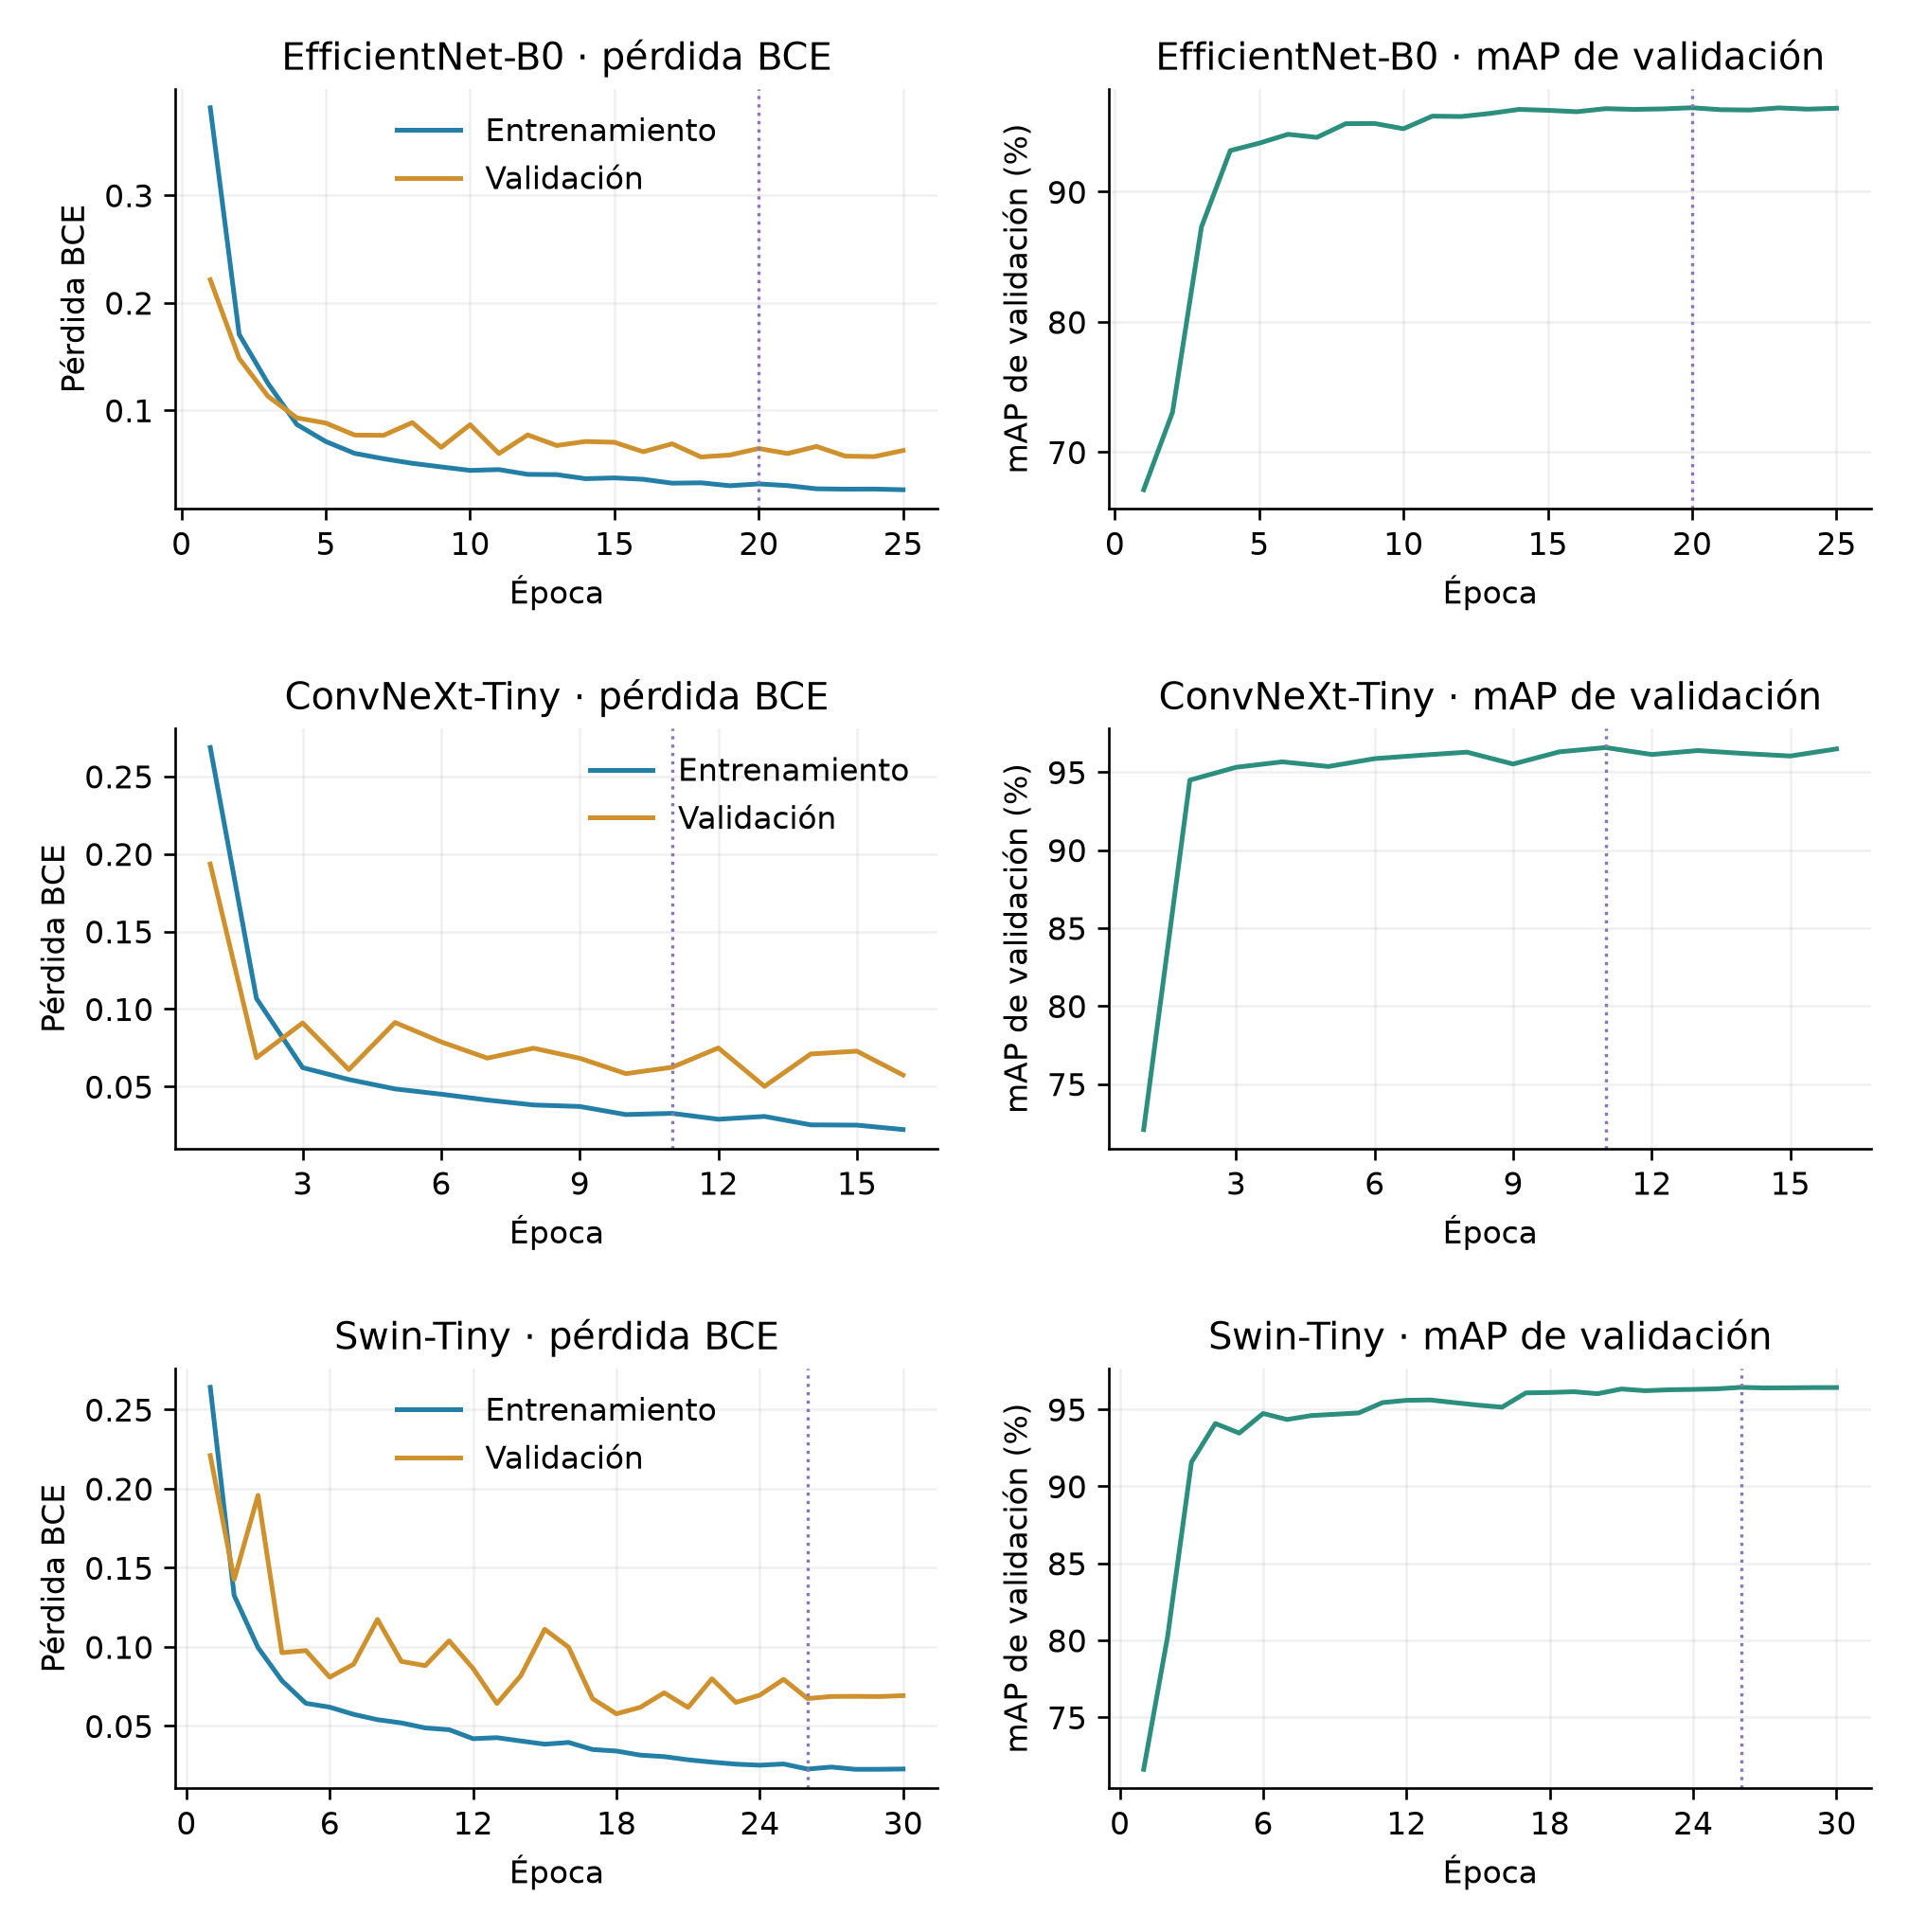

In [10]:
from matplotlib.ticker import MaxNLocator

curve_models = [
    ("efficientnet_b0", "EfficientNet-B0"),
    ("convnext_tiny", "ConvNeXt-Tiny"),
    ("swin_t", "Swin-Tiny"),
]
with plt.rc_context(figure_style(font_size=10)):
    fig, axes = plt.subplots(3, 2, figsize=(8.4, 8.5))
    for row, (model_name, title) in enumerate(curve_models):
        history = histories[model_name]
        run = runs[model_name]
        axes[row, 0].plot(
            history["epoch"], history["train_loss"], color="#247fa6", label="Entrenamiento"
        )
        axes[row, 0].plot(
            history["epoch"], history["val_loss"], color="#ce912d", label="Validación"
        )
        axes[row, 0].set_title(f"{title} · pérdida BCE")
        axes[row, 0].set_ylabel("Pérdida BCE")
        axes[row, 0].legend(frameon=False)
        axes[row, 1].plot(history["epoch"], 100 * history["val_map"], color="#2c8e7c")
        axes[row, 1].set_title(f"{title} · mAP de validación")
        axes[row, 1].set_ylabel("mAP de validación (%)")
        for ax in axes[row, :]:
            ax.set_xlabel("Época")
            ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
            ax.tick_params(axis="x", labelbottom=True)
            ax.axvline(run["best_epoch"], color="#8975b7", linestyle=":", linewidth=1)
            ax.grid(alpha=0.18)
            ax.set_axisbelow(True)
    fig.tight_layout(pad=1.2, h_pad=2.0, w_pad=2.0)
    show_figure(fig, dpi=240, tight=False)